'Forecast daily sales for each Rossmann
store for the next 6 to 7 weeks to support inventory planning and staff scheduling.'

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

Matplotlib is building the font cache; this may take a moment.


In [5]:
train = pd.read_csv("data/raw/train.csv", parse_dates=["Date"], low_memory=False)
store = pd.read_csv("data/raw/store.csv")
test = pd.read_csv("data/raw/test.csv", parse_dates=["Date"])
print(train.shape, store.shape, test.shape)
print("train:", train.Date.min(), "to", train.Date.max())
print("test: ", test.Date.min(), "to", test.Date.max())
train.head()

(1017209, 9) (1115, 10) (41088, 8)
train: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
test:  2015-08-01 00:00:00 to 2015-09-17 00:00:00


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [6]:
df = train.merge(store, on="Store", how="left")
print(df.isna().sum())
print("Closed days share:", (df.Open == 0).mean().round(3))
print("Open but zero sales:", ((df.Open == 1) & (df.Sales == 0)).sum())
print(df.StateHoliday.unique())

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64
Closed days share: 0.17
Open but zero sales: 54
<ArrowStringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str


In [8]:
df["StateHoliday"] = df["StateHoliday"].astype(str)
df["CompetitionDistance"] = df["CompetitionDistance"].fillna(df.CompetitionDistance.max())
for c in ["CompetitionOpenSinceMonth", "CompetitionOpenSinceYear",
"Promo2SinceWeek", "Promo2SinceYear"]:
    df[c] = df[c].fillna(0)
df["PromoInterval"] = df["PromoInterval"].fillna("none")
model_df = df[(df.Open == 1) & (df.Sales > 0)].copy()
print(len(df), "->", len(model_df), "rows kept")

1017209 -> 844338 rows kept


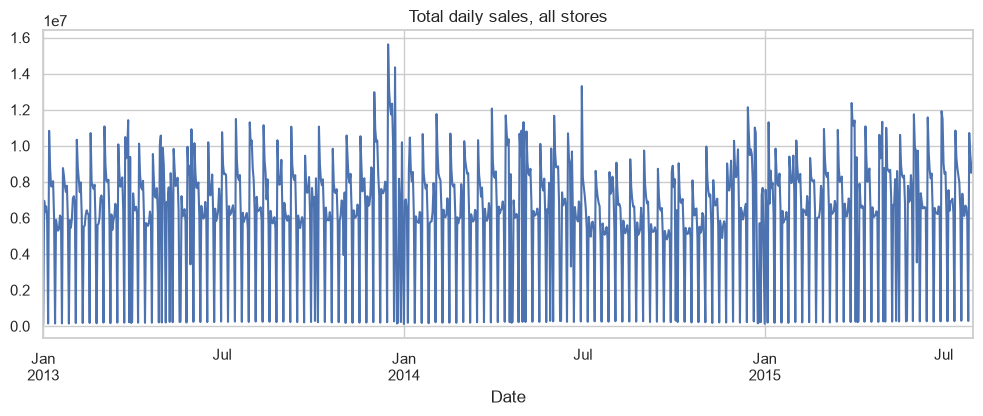

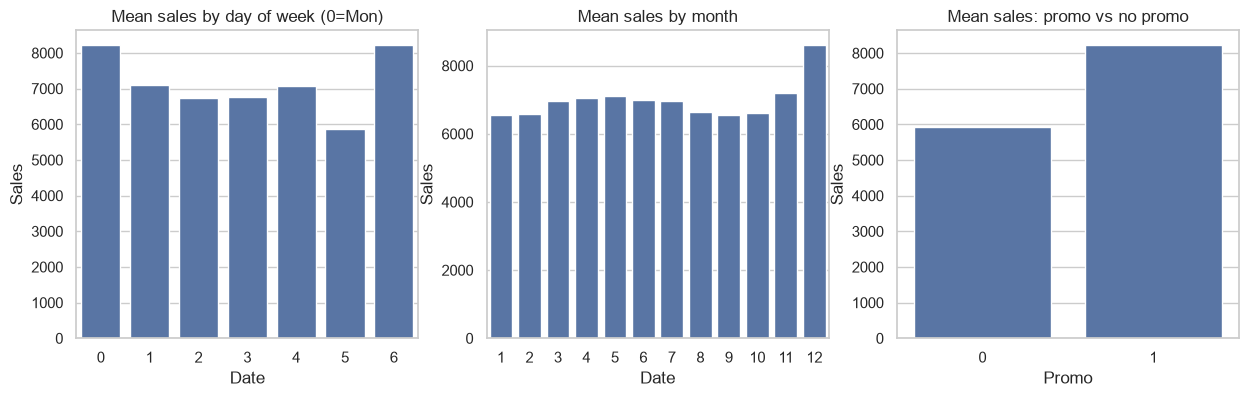

In [12]:
daily = model_df.groupby("Date")["Sales"].sum()
ax = daily.plot(figsize=(12, 4), title="Total daily sales, all stores")
plt.savefig("reports/figures/01_total_sales.png", dpi=150, bbox_inches="tight")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=model_df, x=model_df.Date.dt.dayofweek, y="Sales",
errorbar=None, ax=axes[0]).set_title("Mean sales by day of week (0=Mon)")
sns.barplot(data=model_df, x=model_df.Date.dt.month, y="Sales",
errorbar=None, ax=axes[1]).set_title("Mean sales by month")
sns.barplot(data=model_df, x="Promo", y="Sales",
errorbar=None, ax=axes[2]).set_title("Mean sales: promo vs no promo")
plt.savefig("reports/figures/02_seasonality_promo.png", dpi=150, bbox_inches="tight")

Promo lift: 38.8%


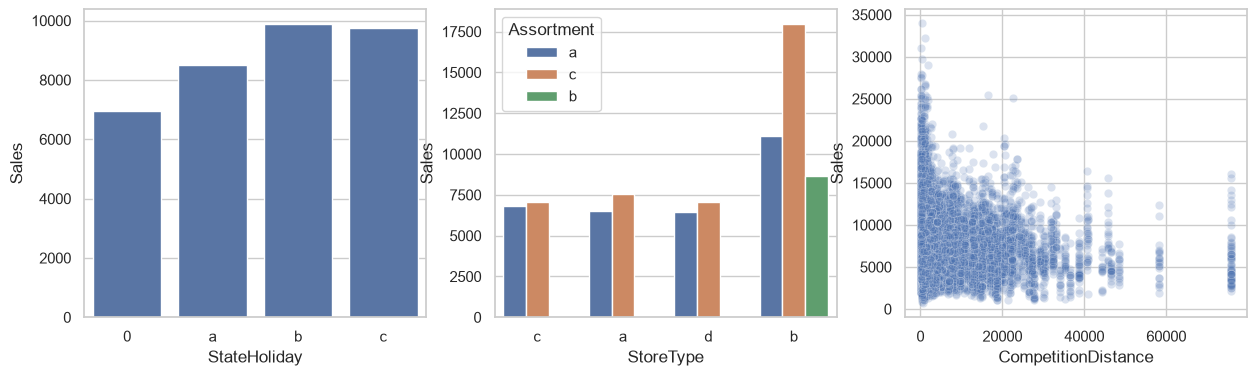

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=model_df, x="StateHoliday", y="Sales", errorbar=None, ax=axes[0])
sns.barplot(data=model_df, x="StoreType", y="Sales", hue="Assortment",
errorbar=None, ax=axes[1])
sns.scatterplot(data=model_df.sample(20000, random_state=1),
x="CompetitionDistance", y="Sales", alpha=0.2, ax=axes[2])
plt.savefig("reports/figures/03_holiday_storetype_competition.png",
dpi=150, bbox_inches="tight")
lift = model_df.groupby("Promo")["Sales"].mean()
print("Promo lift: %.1f%%" % ((lift[1] / lift[0] - 1) * 100))

## Key EDA findings

These averages use days when a store was open and had positive sales.

1. **Promotions coincide with higher sales:** average sales were 8,229 on promo days versus 5,930 on non-promo days, a 38.8% increase. This is an observed difference, not proof that promotions alone caused the increase.
2. **Sales vary by day of week:** Sunday had the highest average (8,225), while Saturday had the lowest (5,875) per store-day. Plan staffing and replenishment around this weekly pattern.
3. **December is the strongest month:** average daily sales were 8,609 per store, 25.9% above the average for all other months, supporting extra seasonal inventory and staffing preparation.
4. **Store type B leads:** its average sales were 10,233 per open store-day, the highest among store types. Consider store format when comparing performance or planning resources.
5. **Competition distance has little linear relationship with sales:** its Pearson correlation with sales was about -0.04, very close to zero. Distance alone is not a useful sales predictor in this dataset.